# 03 — Signatures · Griffiths et al. 2021 (Breast Cancer)

Read the embryonic-module geography on the malignant trajectory and decide **Gate 2**. Deliverable signature
panels show **raw per-cell scores** (smoothing aids the geography read but the panels are raw). Gate 2 GO for a
single Gast/pSom→Crest gradient with terminal Crest (non-branching); Gate 3 = NA with no bifurcation.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('trajectory cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src, l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present' % (l, g.size, feat[src].size))

trajectory cells: 108849 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 100/104 genes present


### Module geography and Gate 2 logic
Read (i) the three pairwise smoothed spatial correlations, (ii) each module's gradient along pseudotime, and
(iii) whether pSom & Crest co-peak (a hub) or exclude (an inverse terminal gradient). A single ordered axis
with organized Gast↔pSom cross-repression and terminal Crest is the **non-branching GO**.

In [4]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print('  %s vs %s: r = %+.3f' % (a, b, r))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[s]); print('  %s: rho = %+.3f' % (s, rho))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print('joint pSom&Crest-high enrichment = %.2f (<1 = inverse gradient, not a hub)' % (joint/exp))
print('\nGATE 2 = GO (non-branching): single (Gast/pSom)->Crest axis, organized Gast<->pSom cross-repression,')
print('         terminal inverse Crest gradient; no Gast/pSom hub diverging into two arms.')
print('GATE 3 = NA: no bifurcation.')
# global module strength -> Linear split
print('global raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict(),
      '-> Linear-pSom/Crest' )

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.426
  Crest_sm vs Gast_sm: r = -0.120
  Crest_sm vs pSom_sm: r = -0.757
gradient along pseudotime (Spearman on smoothed):
  Gast_sm: rho = +0.410
  pSom_sm: rho = -0.397
  Crest_sm: rho = +0.383
Neural-crest-high decile mean pseudotime = 0.77 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.31 (<1 = inverse gradient, not a hub)

GATE 2 = GO (non-branching): single (Gast/pSom)->Crest axis, organized Gast<->pSom cross-repression,
         terminal inverse Crest gradient; no Gast/pSom hub diverging into two arms.
GATE 3 = NA: no bifurcation.
global raw module means: {'Gast': -0.0206, 'pSom': -0.0516, 'Crest': 0.0212} -> Linear-pSom/Crest


### Signature panels — RAW per-cell scores (deliverable) + colorbars

<cell 7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 7>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


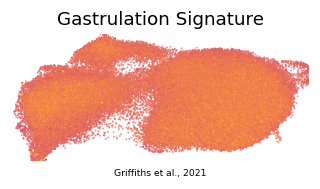

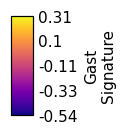

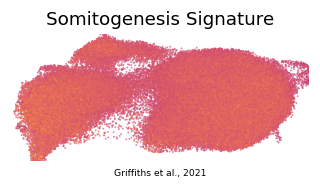

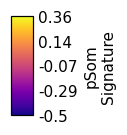

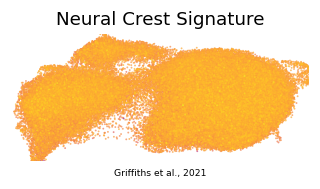

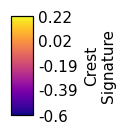

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (108849, 15645)
